# Lab 7: Go-to-goal

**Diyorbek Shokirov, ID 240046**

The robot drives my digits **46** through 11 waypoints with a go-to-goal controller, in the 2D simulator
(`go_to_goal_sim.qrs`) and on the real robot (`go_to_goal_real.qrs`). Same program and gains; only $r$, $B$,
$V_{100}$ and the log name differ. Log: `x,y,time` (cm, cm, ms).

Controller, every loop ($\theta$ = heading from odometry):

$$\rho = \sqrt{(x_g-x)^2 + (y_g-y)^2}, \qquad e = \text{wrap}\big(\text{atan2}(y_g-y,\ x_g-x) - \theta\big)$$

$$v = \min\big(\max(K_v\rho,\ v_{min}),\ v_{max}\big)\cdot\max\big(1 - |e|/e_{drive},\ 0\big), \qquad
\omega = \text{clamp}(K_\theta e,\ \pm\omega_{max})$$

$$v_{R,L} = v \pm \omega\frac{B}{2}, \qquad \text{power}_{R,L} = 100\,\frac{v_{R,L}}{V_{100}}$$

Next waypoint when $\rho < \varepsilon$. $v_{min}$ keeps the wheels above the motor dead zone; the last factor
in $v$ makes the robot turn on the spot first and then drive (sharp corners).

| $K_v$ | $v_{min}$ | $v_{max}$ | $K_\theta$ | $\omega_{max}$ | $e_{drive}$ | $\varepsilon$ |
|---|---|---|---|---|---|---|
| 1.5 1/s | 10 cm/s | 15 cm/s | 4 1/s | 1.5 rad/s | 0.3 rad | 2 cm |

Robot: simulator $r$ = 2.8 cm, $B$ = 15.4 cm, $V_{100}$ = 27 cm/s; real $r$ = 3.75 cm, $B$ = 19.4 cm,
$V_{100}$ = 60 cm/s (Lab 5). $V_{100}$ = wheel speed at 100 % power.

In [1]:
import os
import numpy as np                  # arrays and maths
import matplotlib.pyplot as plt     # plots

if not os.path.exists('odometry_data_sim.txt'):   # only in Colab: upload both txt files first
    from google.colab import files
    uploaded = files.upload()

# waypoints of "46" in cm, same order as in the TRIK program; point 0 = start
wp = np.array([[0, 0], [0, -20], [20, -20], [20, 0], [20, -40],          # the 4
               [40, -40],                                                 # gap
               [40, -20], [60, -20], [60, -40], [40, -40], [40, 0], [60, 0]])   # the 6

# each log line is x, y, time -> three arrays
x_s, y_s, t_s = np.loadtxt('odometry_data_sim.txt',  delimiter=',', unpack=True)   # simulator
x_r, y_r, t_r = np.loadtxt('odometry_data_real.txt', delimiter=',', unpack=True)   # real robot

for name, t in (('simulator', t_s), ('real robot', t_r)):
    print(f'{name}: {len(t)} lines, one loop = {np.diff(t).mean():.0f} ms')   # loop time = time between lines

simulator: 3146 lines, one loop = 10 ms
real robot: 387 lines, one loop = 116 ms


## 1. Trajectories

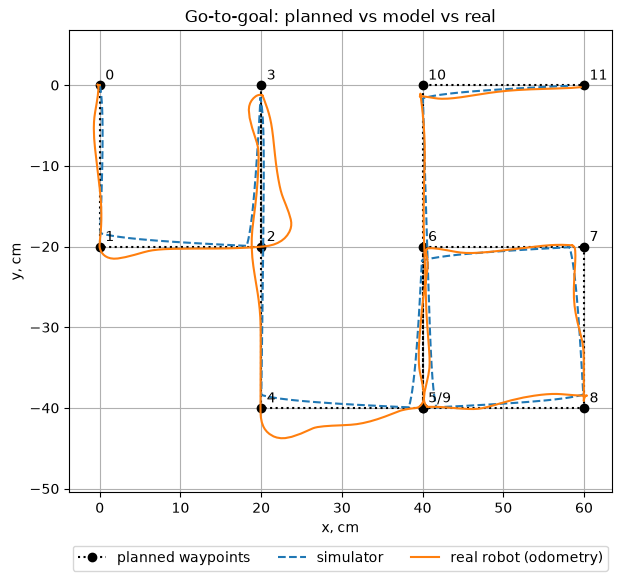

In [2]:
plt.figure(figsize=(7, 6))
plt.plot(wp[:, 0], wp[:, 1], 'k:o', label='planned waypoints')    # the plan
plt.plot(x_s, y_s, '--', label='simulator')                       # dashed = simulator
plt.plot(x_r, y_r,       label='real robot (odometry)')           # solid = where the real robot thinks it drove
for px, py in np.unique(wp, axis=0):                              # number the waypoints (5 and 9 are the same point)
    nums = [str(i) for i, p in enumerate(wp) if p[0] == px and p[1] == py]
    plt.annotate('/'.join(nums), (px, py), textcoords='offset points', xytext=(4, 4))
plt.axis('equal'); plt.grid(True)                                 # equal axes: the 46 is not stretched
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=3)
plt.xlabel('x, cm'); plt.ylabel('y, cm')                          # x = start direction, y = to the left
plt.title('Go-to-goal: planned vs model vs real')
plt.show()

Both runs draw the 46. The simulator turns on the spot and cuts every corner by about 2 cm (ε). The real
robot overshoots a little after some turns: 3.7 cm after corner 2 and 3.8 cm after corner 4.

## 2. Waypoint miss, path error, run time

In [3]:
def waypoint_miss(x, y, wp):            # for each waypoint: the closest the path came to it
    return np.array([np.min(np.hypot(x - px, y - py)) for px, py in wp])

# path error: the planned lines as points every 0.5 cm, then for each logged point the distance to the nearest one
plan = np.vstack([np.linspace(a, b, int(np.hypot(*(b - a)) / 0.5) + 1) for a, b in zip(wp[:-1], wp[1:])])

def path_error(x, y):
    return np.min(np.hypot(x[:, None] - plan[:, 0], y[:, None] - plan[:, 1]), axis=1)

miss_s, miss_r = waypoint_miss(x_s, y_s, wp), waypoint_miss(x_r, y_r, wp)
for i, (ms, mr) in enumerate(zip(miss_s, miss_r)):
    print(f'Waypoint {i:2d} ({wp[i, 0]:2d}, {wp[i, 1]:3d}): sim {ms:4.1f} cm | real {mr:4.1f} cm')

for name, x, y, t in (('sim ', x_s, y_s, t_s), ('real', x_r, y_r, t_r)):
    pe = path_error(x, y)
    print(f'{name}: run time {(t[-1] - t[0]) / 1000:4.1f} s, path error max {pe.max():.1f} cm, mean {pe.mean():.1f} cm')

Waypoint  0 ( 0,   0): sim  0.0 cm | real  0.0 cm
Waypoint  1 ( 0, -20): sim  1.6 cm | real  0.0 cm
Waypoint  2 (20, -20): sim  0.3 cm | real  0.3 cm
Waypoint  3 (20,   0): sim  1.6 cm | real  1.2 cm
Waypoint  4 (20, -40): sim  1.6 cm | real  0.2 cm
Waypoint  5 (40, -40): sim  1.7 cm | real  0.4 cm
Waypoint  6 (40, -20): sim  0.6 cm | real  0.6 cm
Waypoint  7 (60, -20): sim  1.8 cm | real  1.2 cm
Waypoint  8 (60, -40): sim  1.6 cm | real  0.9 cm
Waypoint  9 (40, -40): sim  1.7 cm | real  0.4 cm
Waypoint 10 (40,   0): sim  1.6 cm | real  1.1 cm
Waypoint 11 (60,   0): sim  1.8 cm | real  0.5 cm
sim : run time 31.9 s, path error max 1.5 cm, mean 0.4 cm
real: run time 44.9 s, path error max 3.8 cm, mean 0.7 cm


The simulator misses each corner by 1.6-1.8 cm, just under ε. The real robot gets closer (0-1.2 cm) because
its loop is 116 ms instead of 10 ms, so it rolls about 1 cm further before it switches. The real run is slower
because on the floor it drives about 9 cm/s instead of 12: $V_{100}$ is from Lab 5 with the wheels in the air.

## 3. Measured end point

Start mark on the floor = middle between the wheels; after the run measured with a tape: x forward, y to the left.

In [4]:
x_meas, y_meas = 62, -9                  # tape [cm]

goal = wp[-1]                            # where the robot should stop
odo = np.array([x_r[-1], y_r[-1]])       # where it thinks it stopped (last line of the log)
tape = np.array([x_meas, y_meas])        # where it really stopped

# control error = did it go where it wanted?   localization error = does it know where it is?
print(f'last waypoint: ({goal[0]:5.1f}, {goal[1]:5.1f}) cm')
print(f'odometry end : ({odo[0]:5.1f}, {odo[1]:5.1f}) cm -> {np.hypot(*(odo - goal)):4.1f} cm from the waypoint (control error)')
print(f'tape         : ({tape[0]:5.1f}, {tape[1]:5.1f}) cm -> {np.hypot(*(tape - odo)):4.1f} cm from the odometry (localization error)')

last waypoint: ( 60.0,   0.0) cm
odometry end : ( 59.6,  -0.3) cm ->  0.5 cm from the waypoint (control error)
tape         : ( 62.0,  -9.0) cm ->  9.1 cm from the odometry (localization error)


## 4. Conclusions

In the simulator no corner is overshot; each is cut by about 1.7 cm, which comes from ε = 2 cm. On the real robot
the corners were overshot instead (up to 3.8 cm after corners 2 and 4): it starts driving at |e| = 0.3 rad and
K_θ = 4 corrects the heading late with its 116 ms loop and motor delay, so a smaller e_drive or K_θ should help.
By odometry the real robot ends 0.5 cm from the last waypoint, so control is fine; the 9.1 cm between the tape
and the odometry is a localization problem (wheel slip, inexact r and B), which no controller can fix.